# G9 · Image–text representations with CLIP

**Group G9** · Thi Thu Huyen Dinh, Daniela Birle Mateos, Sebastian Ruano Vila

One model throughout: `openai/clip-vit-base-patch32`, from the Hugging Face CLIP docs
(https://huggingface.co/docs/transformers/model_doc/clip).

| Part | What it shows |
|---|---|
| **A** | Audience question → the Hugging Face example → the answer |
| **B** | Inside CLIP: two encoders, normalised vectors, cosine similarity, temperature |
| **C** | The same CLIP, zero-shot, on 12 colored-shape captions |
| **D** | Held-out experiment: retrain CLIP's final encoder layers on 9 combinations, test on 3 new ones, two training seeds |

**Files needed in the same folder:** this notebook, `g9_helpers.py` (data generation + all plotting) and the
`figures/` folder with the two diagrams. First run downloads CLIP (~600 MB).

In [1]:
# %pip install torch transformers pillow matplotlib numpy     # run once if packages are missing, then restart
import copy
from collections import Counter
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import g9_helpers as helpers

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


## Part A · The Hugging Face example
### A0 · Question for the audience (before any result)

c:\Users\sfrua\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


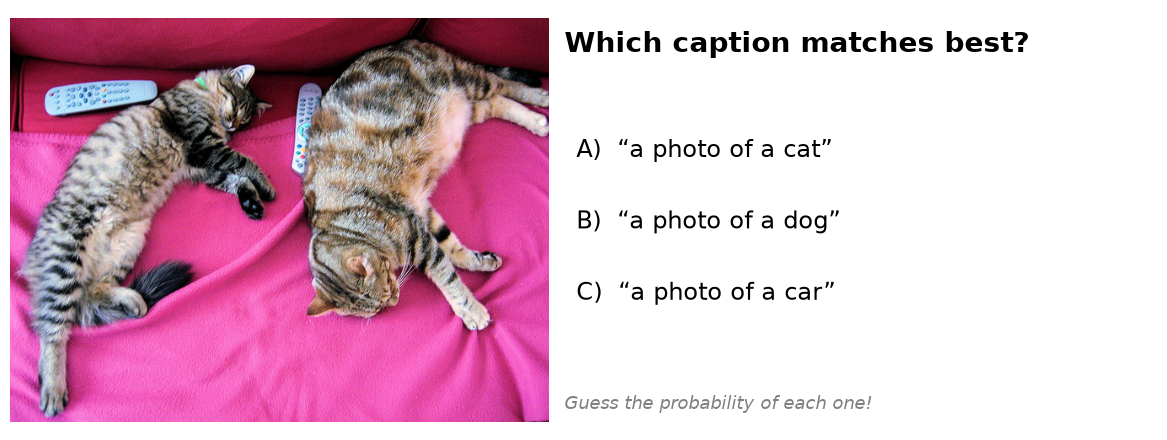

In [2]:
from transformers.image_utils import load_image

url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = load_image(url)
labels = ["a photo of a cat", "a photo of a dog", "a photo of a car"]
helpers.audience_question(image, labels)

### A1 · Pipeline version (from the docs)

In [3]:
from transformers import pipeline

clip = pipeline(task="zero-shot-image-classification", model="openai/clip-vit-base-patch32",
                device=0 if DEVICE == "cuda" else -1)
clip(url, candidate_labels=labels)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 12137.34it/s]


[{'score': 0.9924494028091431, 'label': 'a photo of a cat'},
 {'score': 0.00497177941724658, 'label': 'a photo of a car'},
 {'score': 0.00257877423427999, 'label': 'a photo of a dog'}]

### A2 · Model version (from the docs): the scores behind the answer

In [4]:
from transformers import AutoProcessor, CLIPModel

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
processor = AutoProcessor.from_pretrained("openai/clip-vit-base-patch32")

inputs = processor(text=labels, images=image, return_tensors="pt", padding=True).to(DEVICE)
with torch.inference_mode():
    outputs = model(**inputs)
logits_per_image = outputs.logits_per_image      # image-text similarity scores
probs = logits_per_image.softmax(dim=1)          # probabilities over these 3 candidates

for lab, l, p in zip(labels, logits_per_image[0], probs[0]):
    print(f"{lab:18s} logit = {l:6.2f}   prob = {p:.3f}")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 7619.60it/s]


a photo of a cat   logit =  24.57   prob = 0.993
a photo of a dog   logit =  19.30   prob = 0.005
a photo of a car   logit =  18.48   prob = 0.002


### A3 · The answer for the audience

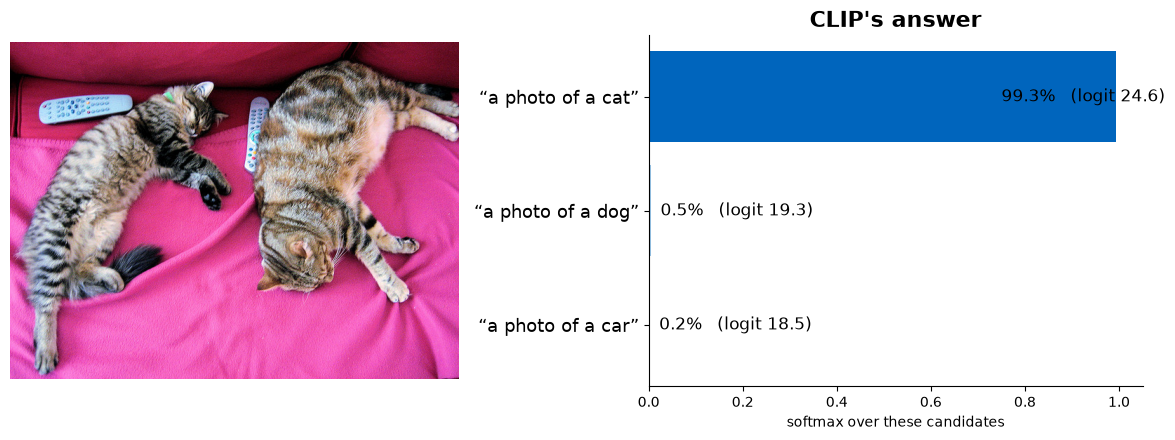

In [5]:
helpers.audience_reveal(image, labels, probs[0].tolist(), logits_per_image[0].tolist())

## Part B · Inside CLIP
![CLIP pipeline](figures/B_clip_pipeline.png)

`model(**inputs)` does four steps. We repeat them by hand and check that we get the same numbers.

1. **Image encoder** (ViT-B/32). Its final layer outputs a 512-number vector.
2. **Text encoder** (Transformer). Its final layer also outputs a 512-number vector.
3. **Normalise** both vectors to length 1. Their dot product is then the **cosine similarity** (between −1 and 1).
4. Divide by the **temperature** (0.01, learned by CLIP) → scores → softmax.

In the Hugging Face code the final layers are called `visual_projection` and `text_projection`.

In [6]:
def encode(images=None, texts=None):
    # Run the frozen encoders, up to (not including) their final layer
    with torch.no_grad():
        img = model.vision_model(**processor(images=images, return_tensors="pt").to(DEVICE)).pooler_output.cpu() if images is not None else None
        txt = model.text_model(**processor(text=texts, return_tensors="pt", padding=True).to(DEVICE)).pooler_output.cpu() if texts is not None else None
    return img, txt

def embed(img_feats, txt_feats, img_layer, txt_layer):
    # Final layer of each encoder, then normalise to length 1
    return F.normalize(img_layer(img_feats), dim=-1), F.normalize(txt_layer(txt_feats), dim=-1)

model.cpu(); DEVICE = "cpu"   # the rest of the notebook runs on CPU
IMG_LAYER, TXT_LAYER = model.visual_projection, model.text_projection

In [7]:
img_feats, txt_feats = encode(images=image, texts=labels)
with torch.no_grad():
    img_vec, txt_vec = embed(img_feats, txt_feats, IMG_LAYER, TXT_LAYER)
    cosine = img_vec @ txt_vec.T
    temperature = 1 / model.logit_scale.exp()
    scores = cosine / temperature

print("image vector:", tuple(img_vec.shape), "| text vectors:", tuple(txt_vec.shape))
print(f"temperature = {temperature.item():.3f}")
for lab, c, s in zip(labels, cosine[0], scores[0]):
    print(f"{lab:18s} cosine = {c:.3f}   / temperature = {s:6.2f}")
print("same as model(**inputs):", torch.allclose(scores, logits_per_image.cpu(), atol=1e-3))

image vector: (1, 512) | text vectors: (3, 512)
temperature = 0.010
a photo of a cat   cosine = 0.246   / temperature =  24.57
a photo of a dog   cosine = 0.193   / temperature =  19.30
a photo of a car   cosine = 0.185   / temperature =  18.48
same as model(**inputs): True


### How CLIP was trained: the contrastive objective
![Pairing diagram](figures/B_pairing_diagram.png)

```python
scores = image @ text.T / temperature
labels = torch.arange(N)                       # the correct pairs are on the diagonal
loss = (F.cross_entropy(scores, labels) + F.cross_entropy(scores.T, labels)) / 2
```
Part D uses exactly this loss.

## Part C · Same CLIP, zero-shot, on colored shapes
4 colors × 3 shapes = **12 captions**, written as `"a photo of a (color + shape)"`. Three combinations are marked
**held-out**: they only matter in Part D. CLIP itself has seen all combinations on the internet.

**Split** (sizes from the course's Mini-CLIP example, 80 / 15 / 30 images per combination):

| Group | Images | Used for |
|---|---|---|
| train | 720 (9 seen × 80) | training in Part D |
| validation | 135 (9 seen × 15) | choosing the best epoch |
| test-seen | 270 (9 seen × 30) | final score, familiar combinations |
| test-held-out | 90 (3 held-out × 30) | final score, new combinations |

The data has its own fixed seed, so the images never change when we change the training seed.

train           720 images
val             135 images
test_seen       270 images
test_held_out    90 images


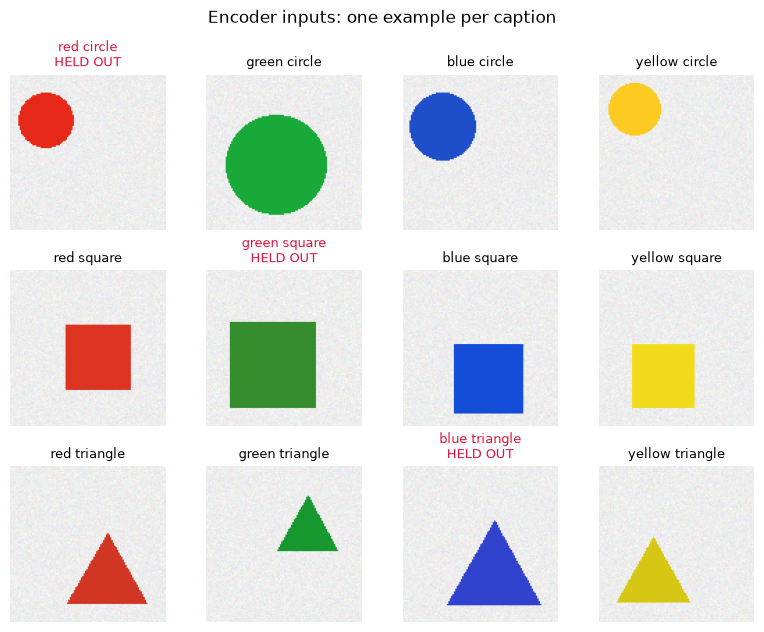

In [8]:
COLORS = ["red", "green", "blue", "yellow"]
SHAPES = ["circle", "square", "triangle"]
CAPTIONS = [f"{c} {s}" for c in COLORS for s in SHAPES]
HELD_OUT = ["red circle", "green square", "blue triangle"]
SEEN = [c for c in CAPTIONS if c not in HELD_OUT]
PROMPTS = [f"a photo of a {c}" for c in CAPTIONS]

DATA = helpers.make_split(CAPTIONS, SEEN, HELD_OUT)
for part, (ims, y) in DATA.items():
    print(f"{part:14s} {len(ims):4d} images")
helpers.show_dataset(DATA, CAPTIONS, HELD_OUT)

### Encode all images and captions once
The encoders stay frozen from here on, so we only need to run them once (takes a few minutes on CPU).

In [9]:
FEATS, LABELS = {}, {}
for part, (ims, y) in DATA.items():
    FEATS[part] = torch.cat([encode(images=ims[i:i + 64])[0] for i in range(0, len(ims), 64)])
    LABELS[part] = y
_, TXT_FEATS = encode(texts=PROMPTS)
print("image features:", tuple(FEATS["train"].shape), "| caption features:", tuple(TXT_FEATS.shape))

image features: (720, 768) | caption features: (12, 512)


In [10]:
ALL = torch.arange(12)
SEEN_IDX = torch.tensor([CAPTIONS.index(c) for c in SEEN])

def predict(img_layer, txt_layer, part, candidates=ALL):
    # Each image picks the caption with the highest cosine similarity
    with torch.no_grad():
        img, txt = embed(FEATS[part], TXT_FEATS[candidates], img_layer, txt_layer)
    return candidates[(img @ txt.T).argmax(dim=1)]

def evaluate(img_layer, txt_layer):
    res = {}
    for part in ["test_seen", "test_held_out"]:
        pred = predict(img_layer, txt_layer, part)
        res[part] = {"pred": pred, "acc": (pred == LABELS[part]).float().mean().item()}
        print(f"{part:14s} accuracy = {res[part]['acc']:.1%}")
    return res

def error_type(true, pred):
    (tc, ts), (pc, ps) = true.split(), pred.split()
    if tc != pc and ts != ps: return "both"
    return "color" if tc != pc else "shape"

def find_errors(res):
    errors = []
    for part, r in res.items():
        for k in (r["pred"] != LABELS[part]).nonzero().flatten().tolist():
            t, p = CAPTIONS[LABELS[part][k]], CAPTIONS[r["pred"][k]]
            errors.append({"part": part, "k": k, "true": t, "pred": p, "kind": error_type(t, p)})
    print("errors:", dict(Counter((e["part"], e["kind"]) for e in errors)))
    for (t, p), n in Counter((e["true"], e["pred"]) for e in errors).most_common(5):
        print(f"  {t:14s} -> {p:15s} x{n}")
    return errors

Pretrained CLIP, zero-shot, 12 candidate captions:
test_seen      accuracy = 88.5%
test_held_out  accuracy = 94.4%
errors: {('test_seen', 'shape'): 31, ('test_held_out', 'shape'): 5}
  red square     -> red triangle    x30
  green square   -> green triangle  x5
  blue square    -> blue triangle   x1


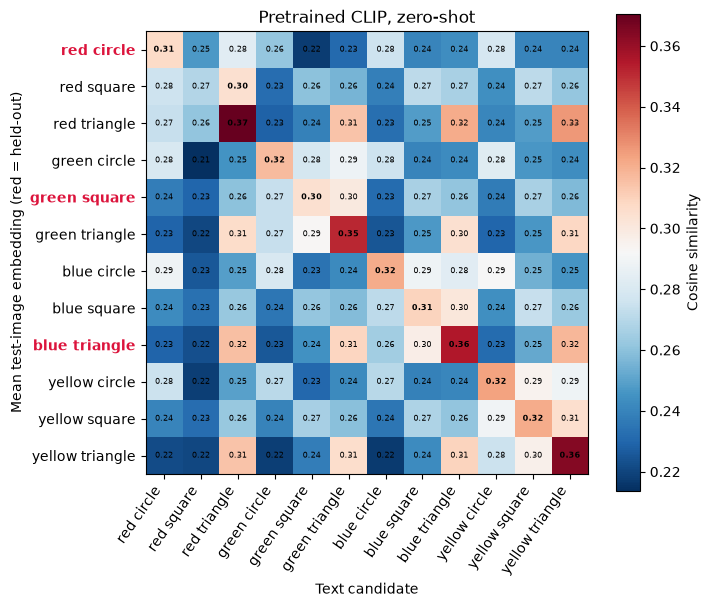

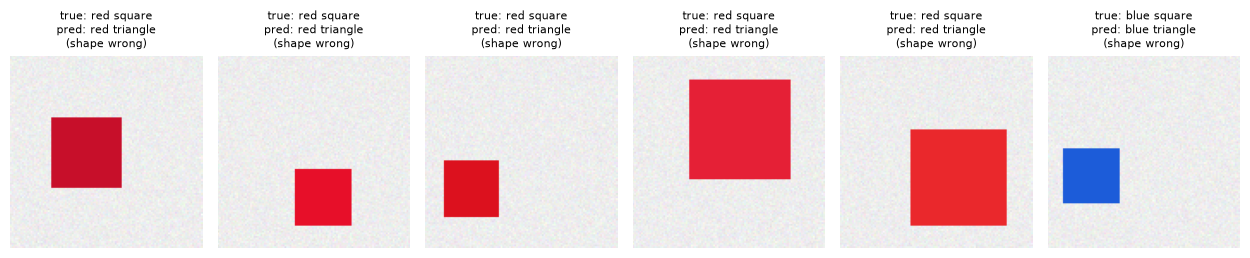

In [11]:
print("Pretrained CLIP, zero-shot, 12 candidate captions:")
zero_shot = evaluate(IMG_LAYER, TXT_LAYER)
zs_errors = find_errors(zero_shot)

def all_test_embeddings(img_layer, txt_layer):
    # held-out images + seen test images together, for the similarity matrix
    feats = torch.cat([FEATS["test_seen"], FEATS["test_held_out"]])
    labels = torch.cat([LABELS["test_seen"], LABELS["test_held_out"]])
    with torch.no_grad():
        img, txt = embed(feats, TXT_FEATS, img_layer, txt_layer)
    return img, labels, txt

helpers.similarity_matrix(*all_test_embeddings(IMG_LAYER, TXT_LAYER), CAPTIONS, HELD_OUT,
                          "Pretrained CLIP, zero-shot", "C_similarity_zero_shot.png")
helpers.show_errors(zs_errors, DATA, "C_errors_zero_shot.png")

## Part D · Held-out combinations experiment
**Question:** if the image–text matching is learned from 9 combinations only, does it recognise the 3 new ones?

* The encoders stay **frozen**. We replace their **final layers** with new, randomly initialised ones
  and train only those, with the contrastive loss from Part B.
* Each training batch = 9 pairs, **one image per seen caption**. The held-out captions are never used in training.
* The best epoch is chosen on validation (seen captions only). Then every test image ranks **all 12 captions**.
* **Our one change: the training seed.** We train twice (seed 0 and seed 1). The data, split, captions and
  temperature stay identical.

In [12]:
def train(seed, epochs=15, lr=1e-3):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    # New final layers: same shape as CLIP's, filled with random numbers
    img_layer, txt_layer = copy.deepcopy(IMG_LAYER), copy.deepcopy(TXT_LAYER)
    for layer in (img_layer, txt_layer):
        nn.init.normal_(layer.weight, std=layer.in_features ** -0.5)
    optimizer = torch.optim.Adam(list(img_layer.parameters()) + list(txt_layer.parameters()), lr=lr)
    temperature = (1 / model.logit_scale.exp()).item()          # CLIP's temperature, 0.01

    images_of = {int(c): (LABELS["train"] == c).nonzero().flatten().numpy() for c in SEEN_IDX}
    best_acc, history = -1, []
    for epoch in range(epochs):
        losses = []
        for step in range(80):                                   # 80 batches x 9 pairs = 720 images
            idx = [rng.choice(images_of[int(c)]) for c in SEEN_IDX]   # one image per seen caption
            img, txt = embed(FEATS["train"][idx], TXT_FEATS[SEEN_IDX], img_layer, txt_layer)
            scores = img @ txt.T / temperature
            targets = torch.arange(len(idx))
            loss = (F.cross_entropy(scores, targets) + F.cross_entropy(scores.T, targets)) / 2
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            losses.append(loss.item())
        val_acc = (predict(img_layer, txt_layer, "val", SEEN_IDX) == LABELS["val"]).float().mean().item()
        history.append((np.mean(losses), val_acc))
        if val_acc > best_acc:                                   # keep the best epoch
            best_acc, best = val_acc, (copy.deepcopy(img_layer), copy.deepcopy(txt_layer))
    print(f"seed {seed}: best validation accuracy {best_acc:.1%}")
    return best[0], best[1], history

seed 0: best validation accuracy 100.0%


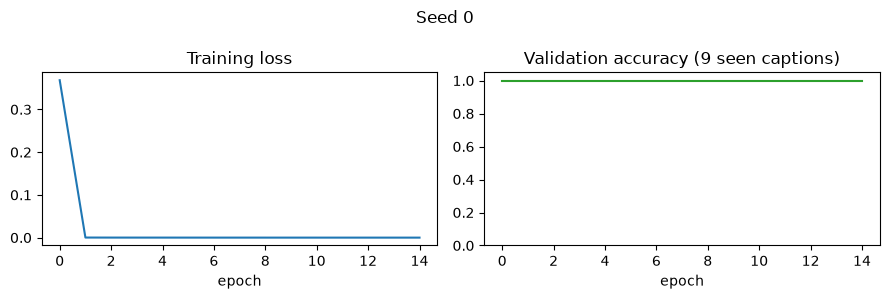

Seed 0, all test images rank the same 12 captions:
test_seen      accuracy = 100.0%
test_held_out  accuracy = 94.4%
   red circle     100%
   green square   100%
   blue triangle  83%
errors: {('test_held_out', 'color'): 4, ('test_held_out', 'both'): 1}
  blue triangle  -> green triangle  x4
  blue triangle  -> green square    x1


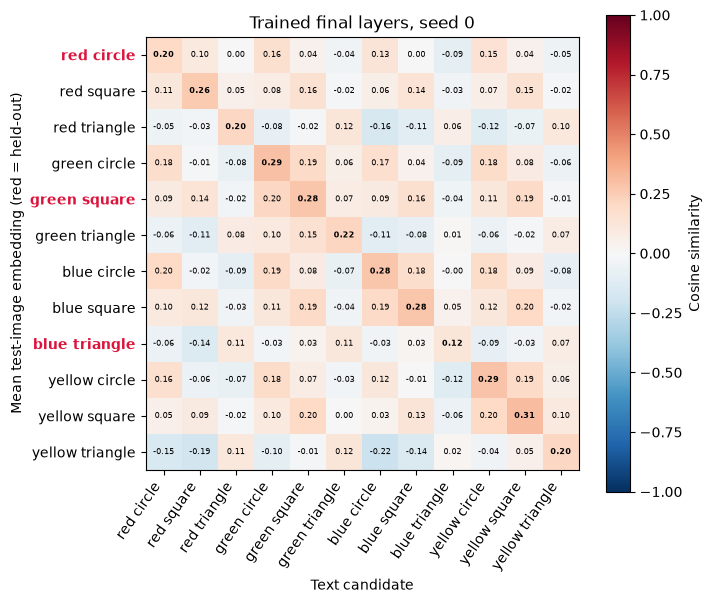

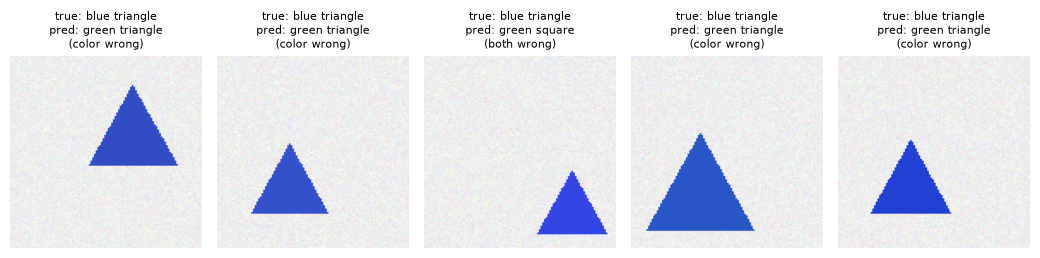

------------------------------------------------------------
seed 1: best validation accuracy 100.0%


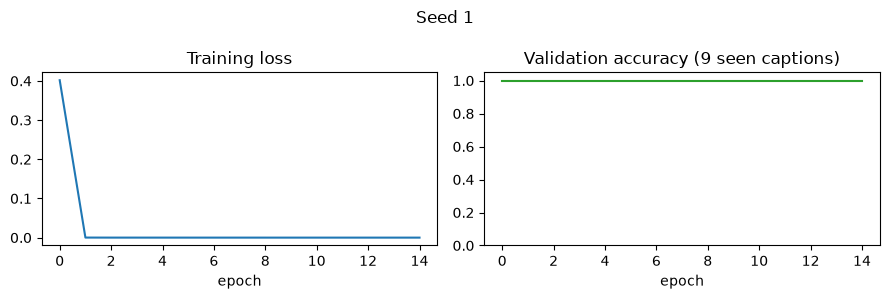

Seed 1, all test images rank the same 12 captions:
test_seen      accuracy = 100.0%
test_held_out  accuracy = 74.4%
   red circle     23%
   green square   100%
   blue triangle  100%
errors: {('test_held_out', 'shape'): 23}
  red circle     -> red square      x23


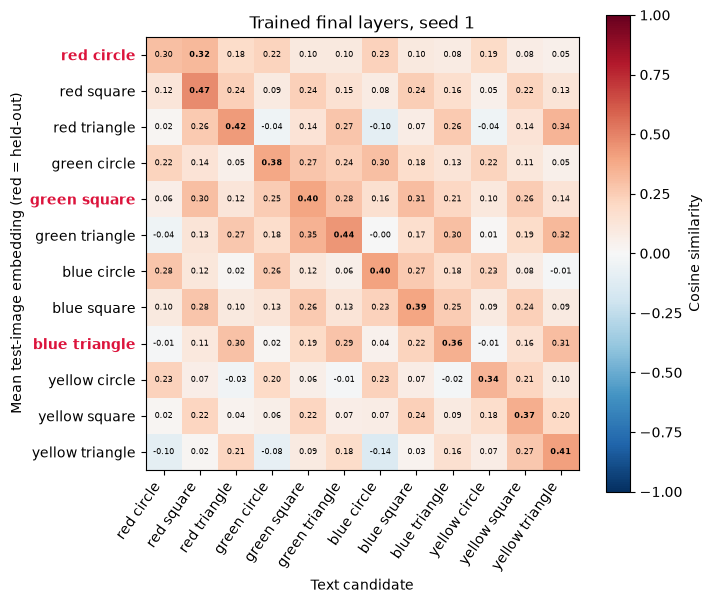

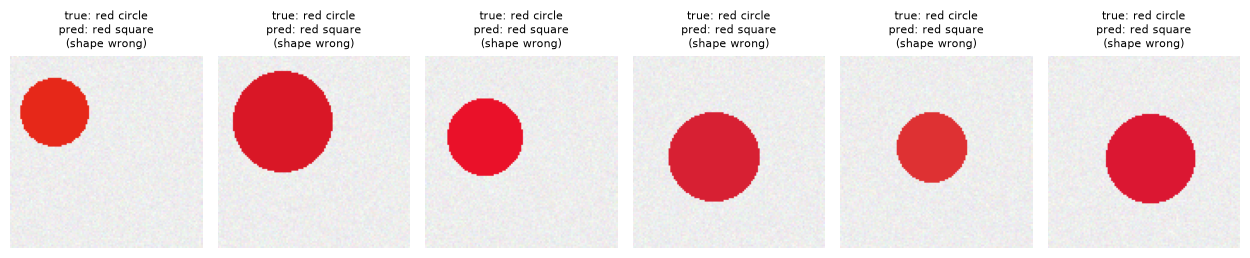

------------------------------------------------------------


In [13]:
runs = {}
for seed in [0, 1]:
    img_layer, txt_layer, history = train(seed)
    helpers.training_curves(history, seed)
    print(f"Seed {seed}, all test images rank the same 12 captions:")
    res = evaluate(img_layer, txt_layer)
    for c in HELD_OUT:
        i = CAPTIONS.index(c); m = LABELS["test_held_out"] == i
        print(f"   {c:14s} {(res['test_held_out']['pred'][m] == i).float().mean():.0%}")
    errors = find_errors(res)
    helpers.similarity_matrix(*all_test_embeddings(img_layer, txt_layer), CAPTIONS, HELD_OUT,
                              f"Trained final layers, seed {seed}", f"D_similarity_seed{seed}.png", -1, 1)
    helpers.show_errors([e for e in errors if e["part"] == "test_held_out"], DATA, f"D_heldout_errors_seed{seed}.png")
    runs[seed] = (res["test_seen"]["acc"], res["test_held_out"]["acc"])
    print("-" * 60)

zero-shot  seen = 88.5%   held-out = 94.4%
seed 0     seen = 100.0%   held-out = 94.4%
seed 1     seen = 100.0%   held-out = 74.4%
difference between the two seeds on held-out: 20 percentage points


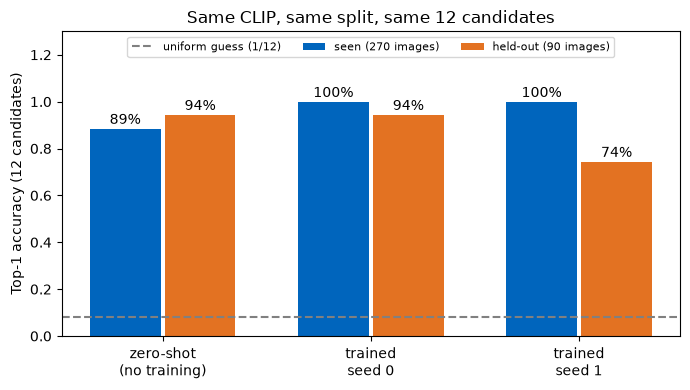

In [14]:
zs = (zero_shot["test_seen"]["acc"], zero_shot["test_held_out"]["acc"])
for name, (s, h) in [("zero-shot", zs)] + [(f"seed {k}", v) for k, v in runs.items()]:
    print(f"{name:10s} seen = {s:.1%}   held-out = {h:.1%}")
print(f"difference between the two seeds on held-out: {abs(runs[0][1] - runs[1][1]) * 100:.0f} percentage points")
helpers.seed_comparison(runs, zs)

## Limitations

* **Only two training seeds.** Two runs show *that* results change with the seed, but not *how much* they
  typically vary. One seed alone could make held-out performance look much better or worse than it usually is.
* **No comparison of how the final layers start.** We always start them from random numbers. Whether starting
  from CLIP's own layers changes the held-out result is not tested here.
* **The encoders were pretrained on ~400M internet image–text pairs** and stay frozen. Part of the held-out
  ability may come from that pretraining rather than from our 9 combinations — this setup cannot separate the two.
* **"Held-out" only means held out from *our* training.** Zero-shot CLIP (Part C) has seen these combinations
  online, so its held-out score is not evidence of compositional generalisation.
* **Prompt wording matters.** "a photo of a red square" can also mean Moscow's Red Square; such text meanings
  from pretraining can cause systematic zero-shot errors.
* **Small test sets.** 90 held-out images give roughly ±5 percentage points of uncertainty overall; a single
  held-out combination (30 images) about ±13. Do not over-interpret differences between single combinations.
* **Synthetic data, one split, fixed temperature (0.01).** Simple shapes on a plain background, generated once;
  results describe this setup only.
* **Softmax "probabilities" are relative to the candidate list** and are not calibrated confidence.